# Integrated Intelligent Systems: Tutorial 2 - Body Motion Problem (Action Designator & URDF) (3 Pts)

This notebook introduces the body motion problem central to designing and implementing Cognition-Enabled Robot Agents.

## Part 1: Action Designator (E1–E6) (1.5 Pt)

**Title:** The Body Motion Problem: Serving Eva a Drink & Breakfast

*The original exercise image `bmp.png` was not included; the full written scenario is reproduced above.*

### Scenario Background
Eva says: "Serve me a drink."

The kitchen contains two milk cartons in the fridge door:
- **Carton A:** Opened whole milk.
- **Carton B:** Unopened oat drink.

Eva's usual mug already contains hot black coffee on the counter.

A wet surface on Carton A causes slip during a low test lift, requiring a grasp adaptation before pouring.

---

### Multi-Question Student Task Sheet (0.25 Pt x 6)

1. **E1 · The Gap & Whole-Course Judgment**
   - Eva says "Serve me a drink." A video shows a robot executing a smooth trajectory, placing the mug on the table, but a photograph reveals milk spilled across the counter and an open fridge left behind. Explain why this nominal end-state success does **not** constitute a solution to the Body Motion Problem, and specify two whole-course constraints that were violated.

2. **E2 · Constrained Action Designator & Grounding**

    - Distinguish interpretation, inferred means, and grounded objects for this episode by filling out the three missing slots in the schematic action designator:
    
    - **Working Interpretation:** `(:type serving) (:recipient Eva) (:substance ________)`
    - **Inferred Function/Means:** `(:vessel-role ________)`
    - **Grounded Physical Object:** `(:object ________)`

3. **E3 · The Commitment Decision & Asymmetric Failure Costs**

    - During the retrieval step, the robot faces a choice between a **5 mm test lift near the shelf** or a **high carry directly to the counter**. State the predicted effect, the cost of failure, and the single piece of evidence that justifies choosing the low test lift before committing to the carry.

4. **E4 · Causal Prediction across Material Variants**

    - Compare pouring milk into coffee versus pancake batter into a pan. Formulate the stopping rule for each liquid using `(:stop-when ...)`, and explain how material dynamics alter when the robot must command the wrist to tilt back.

5. **E5 · System Decomposition & The Reasoning Loop**

    - Trace the carton slip event through the seven-stage reasoning loop: **Infer → Ground → Predict → Decide → Regulate → Detect & Revise → Verify**. State precisely which step was triggered when downward motion was observed during the 5 mm lift, and how the action designator was developed in response.

6. **E6 · Conceptual Ablation & Evidence of Competence**

    - Perform an ablation experiment. Suppose we remove the **"Check before commitment"** capability and replace it with a fixed default high-side-pinch lift. Predict a specific kitchen environment variant where this ablated system fails, and explain why single-run execution success differs from evidence of general competence across task variants.

### Solutions — Part 1 (E1–E6)

#### E1 · The Gap & Whole-Course Judgment
A smooth trajectory and an apparently correct final mug position are insufficient. The **body motion problem** requires the *entire course* of the action to bring about the intended effect without violating constraints. Here, (1) spilling milk violates the cleanliness/no-spill constraint, and (2) leaving the fridge open violates the requirement to restore the environment (and may compromise storage conditions). The final photograph cannot establish successful, acceptable execution over time.

#### E2 · Constrained Action Designator & Grounding
- **Working interpretation:** `(:type serving) (:recipient Eva) (:substance coffee-with-milk)` — a **provisional** reading of the request, to be confirmed with Eva; “serve me a drink” alone does not specify coffee with milk.
- **Inferred function/means:** `(:vessel-role containing-and-delivering-the-drink)` — a vessel is inferred because liquid needs containment and support.
- **Grounded physical object:** `(:object Eva-usual-mug-on-counter)` — the specific mug observed on the counter, already containing black coffee. The opened whole-milk carton is another candidate object for obtaining milk, *not* the vessel containing the served drink.

The three levels are not interchangeable: **interpretation** specifies intended outcome, **means** supplies a functional requirement, and **grounding** binds that role to a particular observed object. Verify that Eva actually wants milk rather than assuming it from habit.

#### E3 · The Commitment Decision & Asymmetric Failure Costs
- **5 mm test lift:** predicted effect: briefly lift Carton A near the supporting shelf to test whether the chosen grasp can withstand its weight. A slip can be detected early with limited drop height and an available support surface.
- **High carry directly to the counter:** predicted effect: transfer the carton sooner if the grasp holds, but if the wet carton slips it may fall farther, spill milk, damage objects, or create a hazard.
- **Evidence for the safer commitment:** the *observed downward slip* during the 5 mm test lift is direct evidence that the wet-carton side pinch is not reliable under these conditions. Before the lift, known wetness/uncertain friction justifies *testing* rather than confidently committing to the high carry; after slip is detected, it justifies changing the grasp. In a strict timeline, the slip observation cannot be evidence for choosing the test that generated it.

#### E4 · Causal Prediction across Material Variants
- **Milk into coffee:** `(:stop-when (predicted-final-fill >= desired-fill))`, subject to `(:constraint (no-spill))`. Command the wrist to start tilting back **before** reaching the target volume, accounting for fluid still moving after the command and control/measurement delay.
- **Pancake batter into a pan:** `(:stop-when (predicted-final-spread >= desired-disc-size))`, subject to `(:constraint (no-overflow-or-excess-spread))`. Because batter is more viscous and spreads differently, the robot must predict the delayed outflow and subsequent spread; the tilt-back point depends on batter viscosity, residual flow and the desired pancake footprint, rather than coffee fill level.

Both are **predictive** stopping conditions; stopping at the visual target may overshoot. No universal stop-time can be inferred without measured dynamics.

#### E5 · System Decomposition & The Reasoning Loop
1. **Infer:** Serving Eva requires obtaining a suitable drink and transporting the needed liquid, so a grasp-and-carry operation is considered.
2. **Ground:** Identify Carton A (opened whole milk) in the fridge, observe the wet surface, and associate the action with that specific carton; confirm beverage preference where needed.
3. **Predict:** The side pinch may have insufficient friction. A short low test lift offers evidence at limited risk; a high carry carries more severe failure costs.
4. **Decide:** Choose a low 5 mm test lift, not an immediate high carry.
5. **Regulate:** Execute the commanded lift with joint/gripper feedback and monitor the carton relative to the fingers.
6. **Detect & Revise:** **This is the step triggered by observed downward slip** during the test lift. Update the belief that the side pinch is unreliable; put the carton back on its support, and **develop the action designator** from `(:grasp side-pinch)` to `(:grasp bottom-support)`, with a possible later regrasp for the pour.
7. **Verify:** Test the revised grasp, check that the carton is supported during transfer, and later verify the poured amount, safe placement and fridge closure.

A **belief update** (grasp may slip), **designator revision** (bottom support and later regrasp), and **physical transition** (actual slip/set-down) are three different events.

#### E6 · Conceptual Ablation & Evidence of Competence
Consider a wet or condensation-covered milk carton with lower contact friction than the dry cartons used in prior demonstrations. Without **check before commitment**, a fixed high side-pinch lift may slip during the elevated transfer and drop or spill the carton. The full system can use a low test lift, detect slip, and revise to bottom support before high transport. A single successful dry-carton run establishes only that the policy succeeded *in that episode*; competence requires repeated evidence across declared variants (e.g., dry/wet surfaces, mass/fill differences, altered positions), explicit success and safety criteria, and records of failure handling. Removing the check makes generalization to the wet case unwarranted.


## Part 2: Kino-Dynamic Modeling of Robot World System with URDF (1.5 Pt)

**Title:**  Designing and Implementing the kino-dynamic model of the robot world system with URDF

### 2.1  Theoretical Background

In [1]:
from IPython.display import display, HTML,IFrame
display(IFrame('urdf_background.html', width=1000, height=2000))

## 2.2  Hands-on: Model your own robot world system according to specifications below (1.5 Pt)

In [2]:
from IPython.display import display, HTML,IFrame
display(IFrame('urdf_handon.html', width=1000, height=2000))

### Part 2 — Completed URDF/Xacro design (official requirements)

The attached **URDF Design Challenge: Serving Eva a Drink** requires a modular robot with three component files (`base.xacro`, `arm.xacro`, `gripper.xacro`) and one assembly file (`robot.xacro`). This submission implements a **fixed cylindrical pedestal**, a **three-DOF revolute arm** (shoulder pitch, elbow pitch, wrist pitch), and a **two-finger parallel gripper** with independently actuated prismatic joints. The wrist joint enables a tilting motion suitable for a pouring posture. The arm operates in the x-z plane; the base is positioned such that the fridge target and counter target lie in that plane. This is an idealized robot model, not a full simulation of a fridge door or liquid flow.

**Task dimensions from the specification:** fridge shelf heights 0.4–1.2 m; target lower grasp height **0.4 m**; carton **0.10 × 0.10 × 0.20 m**; counter surface **0.9 m**; target pour height **1.0 m**; mug radius **0.08 m** and height **0.12 m**. The model parameters are `base_radius=0.18 m`, `base_height=0.72 m`, `link1_length=0.48 m`, `link2_length=0.42 m`, and `gripper_span=0.14 m`. Gripper aperture at full opening is 0.14 m, which exceeds the carton width of 0.10 m by 0.04 m. The 0.4 m and 1.0 m targets are verified by planar inverse kinematics below.

The final expanded `robot.urdf` is provided for viewers that do not support Xacro. The included `expand_xacro.py` is a small **offline** expander supporting the constructs used here; in a normal ROS environment, the canonical command is `xacro robot.xacro > robot.urdf`.

In [3]:
from pathlib import Path
import xml.etree.ElementTree as ET

# The folder containing this notebook is also the URDF/Xacro project folder.
files = ['base.xacro', 'arm.xacro', 'gripper.xacro', 'robot.xacro', 'robot.urdf']
for name in files:
    assert Path(name).is_file(), f'Missing file: {name}'
    ET.parse(name)

xns = '{http://www.ros.org/wiki/xacro}'
main = ET.parse('robot.xacro').getroot()
includes = [item.attrib['filename'] for item in main.findall(xns + 'include')]
assert set(includes) == {'base.xacro', 'arm.xacro', 'gripper.xacro'}
robot = ET.parse('robot.urdf').getroot()
links = {l.get('name') for l in robot.findall('link')}
joints = robot.findall('joint')
for j in joints:
    assert j.find('parent').get('link') in links
    assert j.find('child').get('link') in links
    if j.get('type') in ('revolute', 'prismatic'):
        assert j.find('axis') is not None and j.find('limit') is not None
assert len([j for j in joints if j.get('type') == 'revolute']) == 3
assert len([j for j in joints if j.get('type') == 'prismatic']) == 2
assert len(links) == 7
print('Four Xacro modules verified,', len(links), 'links and', len(joints), 'joints in URDF.')

Four Xacro modules verified, 7 links and 6 joints in URDF.


#### Reach verification at both required heights

The wrist frame at the end of the two arm links is the chosen reference for the assignment's target end-effector height. In the vertical plane, with `q1` and `q2` the shoulder/elbow angles and `q3` the wrist pitch,

\[x = L_1\cos(q_1)+L_2\cos(q_1+q_2),\quad z = h_b-L_1\sin(q_1)-L_2\sin(q_1+q_2).\]

The inverse kinematics check below uses the two-link law of cosines to produce configurations for selected horizontal distances from the pedestal. The third joint is adjusted to keep the gripper approximately horizontal while grasping and to tilt it for pouring. A point reachability check alone is not proof of collision-free motion or physical pouring.

In [4]:
import math
import numpy as np

BASE_HEIGHT, LINK1, LINK2, GRIPPER_SPAN = 0.72, 0.48, 0.42, 0.14
CARTON_WIDTH = 0.10
assert GRIPPER_SPAN > CARTON_WIDTH

def forward_kinematics(q, l1=LINK1, l2=LINK2, h=BASE_HEIGHT):
    q1, q2, q3 = q
    x1, z1 = l1 * np.cos(q1), h - l1 * np.sin(q1)
    x2 = x1 + l2 * np.cos(q1+q2)
    z2 = z1 - l2 * np.sin(q1+q2)
    return np.array([[0, h], [x1, z1], [x2, z2]]), float(q1+q2+q3)

def inverse_kinematics(x, z, l1=LINK1, l2=LINK2, h=BASE_HEIGHT):
    # Standard 2R IK with an x-z convention where positive q rotates toward -z.
    dy = h-z
    D = (x*x + dy*dy - l1*l1 - l2*l2)/(2*l1*l2)
    if not -1 <= D <= 1:
        raise ValueError(f'Target ({x:.2f}, {z:.2f}) outside arm workspace')
    for q2 in (math.acos(D), -math.acos(D)):
        q1 = math.atan2(dy,x) - math.atan2(l2*math.sin(q2),l1+l2*math.cos(q2))
        q3 = -q1-q2
        if abs(q1) <= 2.5 and abs(q2) <= 2.8 and abs(q3) <= 2.5:
            return np.array([q1,q2,q3])
    raise ValueError('Target not reachable inside joint angle limits')

# Horizontal locations are explicit design assumptions, not specified in the handout.
targets = {'Milk carton / fridge': (0.55, 0.40), 'Mug / counter': (0.65, 1.00)}
poses = {}
for label,(x,z) in targets.items():
    q = inverse_kinematics(x,z)
    points, angle = forward_kinematics(q)
    assert np.allclose(points[-1], [x,z], atol=1e-9)
    poses[label] = q
    print(f'{label}: target x={x:.2f} m, z={z:.2f} m; joint angles (deg) = {np.round(np.rad2deg(q), 1)}')
print(f'Open finger gap: {GRIPPER_SPAN:.2f} m > {CARTON_WIDTH:.2f} m carton width')

Milk carton / fridge: target x=0.55 m, z=0.40 m; joint angles (deg) = [-11.1  90.3 -79.2]
Mug / counter: target x=0.65 m, z=1.00 m; joint angles (deg) = [-58.5  76.5 -18. ]
Open finger gap: 0.14 m > 0.10 m carton width


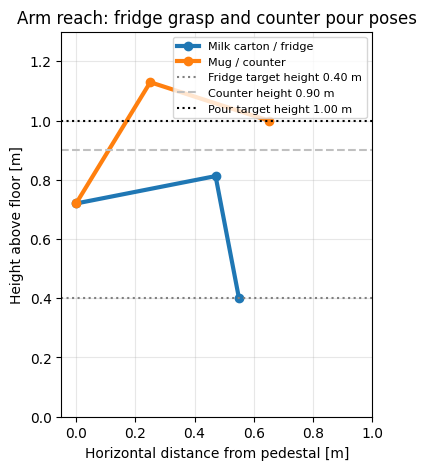

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 5))
for label, q in poses.items():
    pts, _ = forward_kinematics(q)
    ax.plot(pts[:,0], pts[:,1], 'o-', linewidth=3, label=label)
ax.axhline(0.40, color='gray', linestyle=':', label='Fridge target height 0.40 m')
ax.axhline(0.90, color='silver', linestyle='--', label='Counter height 0.90 m')
ax.axhline(1.00, color='black', linestyle=':', label='Pour target height 1.00 m')
ax.set(xlabel='Horizontal distance from pedestal [m]', ylabel='Height above floor [m]',
       title='Arm reach: fridge grasp and counter pour poses', xlim=(-0.05,1.0), ylim=(0,1.3))
ax.set_aspect('equal', adjustable='box'); ax.legend(loc='upper right', fontsize=8); ax.grid(alpha=0.3)
plt.show()

#### Parameter flexibility (requested defense)

Changing `link1_length` in `robot.xacro` must update the upper-arm geometry **and** the next joint's transform. Since `arm.xacro` defines both with `${link1_length}`, they stay consistent. The demonstration below regenerates URDF using a changed first-link length and compares its geometry with the elbow-joint offset. It uses the included offline expander for environments without ROS; regular ROS installations should use the official Xacro tool.

In [6]:
from expand_xacro import expand

def upper_length_and_elbow_offset(robot_root):
    upper = next(l for l in robot_root.findall('link') if l.get('name') == 'upper_arm')
    length = float(upper.find('./visual/geometry/cylinder').get('length'))
    elbow = next(j for j in robot_root.findall('joint') if j.get('name') == 'elbow_pitch')
    origin_x = float(elbow.find('origin').get('xyz').split()[0])
    return length, origin_x

standard = expand('robot.xacro')
modified = expand('robot.xacro', link1_length=0.54)
assert np.allclose(upper_length_and_elbow_offset(standard), [0.48, 0.48])
assert np.allclose(upper_length_and_elbow_offset(modified), [0.54, 0.54])
print('Changing link1_length from 0.48 to 0.54 m changes both link geometry and elbow offset.')

Changing link1_length from 0.48 to 0.54 m changes both link geometry and elbow offset.


#### Design justification and limitations

**Component composition:** the base is defined in `base.xacro`, shoulder/elbow/wrist and their segments in `arm.xacro`, and the two-finger parallel gripper in `gripper.xacro`. `robot.xacro` includes and instantiates all three modules. The model uses Xacro properties and `${...}` expressions rather than separately hardcoding dimensions at every joint. The original two HTML files are stored alongside the notebook for the background/assignment iframe cells.

**Physical task:** the robot can position its wrist frame at the required 0.4 m and 1.0 m heights; a 0.14 m fully open gripper clears the 0.10 m carton; the wrist has a revolute tilt for a possible pour. The model assumes the fridge and counter can be approached along the arm's vertical plane and that the fridge door is already open. The files demonstrate *geometric feasibility*, not a complete physics-based grasp/pour controller. Collision-free trajectories, grip forces on wet cartons, actual liquid transfer, and Eva's preferences still need perception, planning and control. A scene/environment model is not required among the four Xacro deliverables.

# Submission guidelines

- Deadline: 17.11.2026, 4 PM
- Submission as Git repo commits pushed within deadlines (If not yet, create a repo with the name **iis-assignment-win26** for the whole semester and invite me as collaborator)
- Put the textual answers in notebook and all related media (urdf, xacro, etc) should then be put into a folder called **Assignment2**. 